In [ ]:
# Change '/content/drive/MyDrive' to any subfolder path you want to list
# !ls "/content/drive/MyDrive/BMEN600"
# folder = ...

In [19]:
import pandas as pd
import os
from scipy.io import loadmat
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [ ]:
#Variables in the file
file_path = os.path.join(folder, "S010_ex1.mat") # Find the file path

data = loadmat(file_path) # Load file path

print("Variables in the file:")
for key, value in data.items():
    if not key.startswith("__"):
        print(
            key,
            "Shape:", getattr(value, "shape", None), #Shape = Number os rows, columns
            "Type:", type(value) #Type of values in column
        )

In [ ]:
variables = [
    "ts", "tobiits", "emg", "gazepoint",
    "grasp", "object", "grasprepetition",
    "objectrepetition", "gazepoint_invalid"
]

for name in variables:
    arr = np.asarray(data[name])
    print(f"\n{name}: dtype={arr.dtype}, shape={arr.shape}")
    print(arr[:5])

In [21]:

# Table 2: grasp ID -> grasp name
grasp_names = {
    1: "Medium wrap",
    2: "Lateral",
    3: "Parallel extension",
    4: "Tripod grasp",
    5: "Power sphere",
    6: "Precision disk",
    7: "Prismatic pinch",
    8: "Index finger extension",
    9: "Adducted thumb",
    10: "Prismatic four finger"
}

# Table 2: object ID -> object name
object_names = {
    1: "Bottle",
    2: "Can",
    3: "Door handle",
    4: "Mug",
    5: "Key",
    6: "Pencil case",
    7: "Plate",
    8: "Book",
    9: "Drawer",
    12: "Ball",
    13: "Bulb",
    16: "Clothespin",
    18: "Knife",
    19: "Fork",
    20: "Screwdriver",
    21: "Remote",
    22: "Wrench"
}

In [22]:
dynamic = np.asarray(data["dynamic"]).ravel()

# Select static-condition samples (dynamic == 0)
static = dynamic == 0

In [23]:
regrasp = np.asarray(data["regrasp"]).ravel()
object_repetition = np.asarray(data["objectrepetition"]).ravel()
emg = np.asarray(data["emg"])

mask = (
    static &
    (~np.isin(object_repetition, [-3, -2])) &
    (regrasp >= 1) &
    (regrasp <= 10)
)

In [12]:
import numpy as np
import pandas as pd

# Identify samples from the static condition
dynamic = np.asarray(data["dynamic"]).ravel()
static_mask = dynamic == 0

# Extract grasp and object IDs for static samples
static_labels = pd.DataFrame({
    "grasp_id": np.asarray(data["grasp"]).ravel()[static_mask],
    "object_id": np.asarray(data["object"]).ravel()[static_mask]
})

# Map numeric IDs to readable names
static_labels["grasp_name"] = static_labels["grasp_id"].map(grasp_names)
static_labels["object_name"] = static_labels["object_id"].map(object_names)

# Display unique grasp/object combinations
label_combinations = (
    static_labels[
        ["grasp_id", "grasp_name", "object_id", "object_name"]
    ]
    .drop_duplicates()
    .sort_values(["grasp_id", "object_id"])
    .reset_index(drop=True)
)

display(label_combinations)

,grasp_id,grasp_name,object_id,object_name
0,0,NaN,1,Bottle
1,0,NaN,2,Can
2,0,NaN,3,Door handle
3,0,NaN,4,Mug
4,0,NaN,5,Key
5,0,NaN,7,Plate
6,0,NaN,8,Book
7,0,NaN,9,Drawer
8,0,NaN,12,Ball
9,0,NaN,13,Bulb


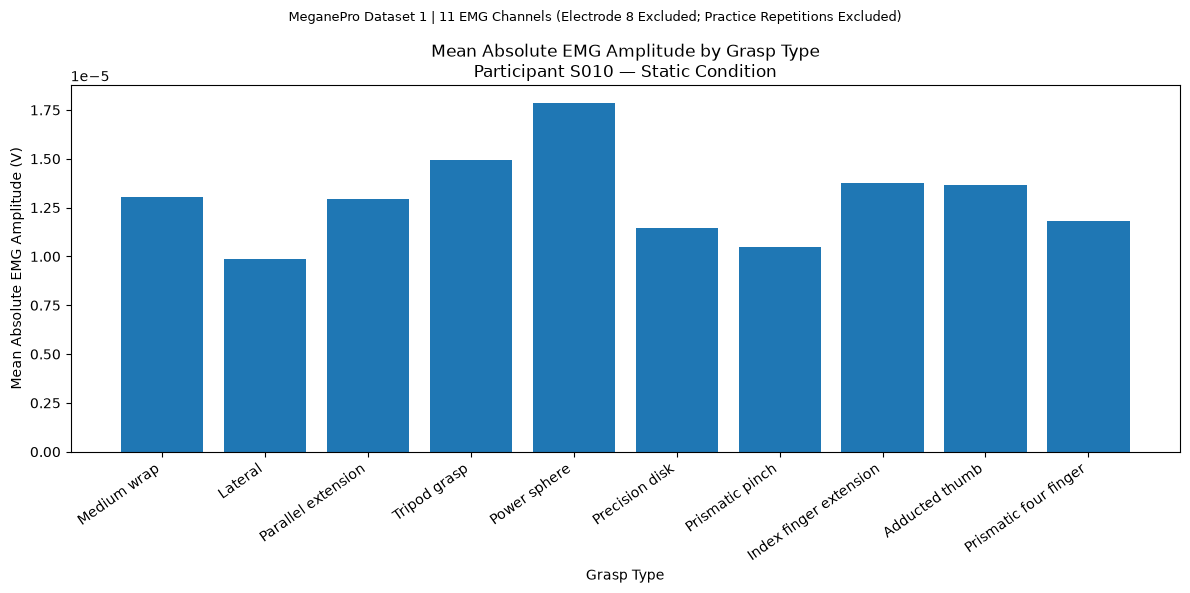

Samples analyzed: 2435070

Mean absolute EMG amplitude by grasp type:
grasp_id
Medium wrap               0.000013
Lateral                   0.000010
Parallel extension        0.000013
Tripod grasp              0.000015
Power sphere              0.000018
Precision disk            0.000011
Prismatic pinch           0.000010
Index finger extension    0.000014
Adducted thumb            0.000014
Prismatic four finger     0.000012
Name: emg_magnitude, dtype: float32


In [20]:
# grasp_labels_text = [grasp_names[i] for i in summary.index]

# Read arrays from S010
dynamic = np.asarray(data["dynamic"]).ravel()
regrasp = np.asarray(data["regrasp"]).ravel()
object_repetition = np.asarray(data["objectrepetition"]).ravel()
emg = np.asarray(data["emg"])

# Keep static samples, excluding unreliable practice repetitions
mask = (
    (dynamic == 0) &
    (~np.isin(object_repetition, [-3, -2])) &
    (regrasp >= 1) &
    (regrasp <= 10)
)

# Exclude electrode 8 (Python index 7)
emg_filtered = np.delete(emg[mask, :], 7, axis=1)
grasp_labels = regrasp[mask]

# Mean absolute amplitude across the remaining 11 channels
sample_magnitude = np.mean(np.abs(emg_filtered), axis=1)

results = pd.DataFrame({
    "grasp_id": grasp_labels,
    "emg_magnitude": sample_magnitude
})

# Calculate mean amplitude for each grasp
summary = (
    results.groupby("grasp_id")["emg_magnitude"]
    .mean()
    .reindex(range(1, 11))
)

# Replace IDs with grasp names
grasp_labels_text = [grasp_names[i] for i in summary.index]

# Plot
plt.figure(figsize=(12, 6))
plt.bar(grasp_labels_text, summary.values)

plt.xlabel("Grasp Type")
plt.ylabel("Mean Absolute EMG Amplitude (V)")
plt.title(
    "Mean Absolute EMG Amplitude by Grasp Type\n"
    "Participant S010 — Static Condition"
)
plt.suptitle(
    "MeganePro Dataset 1 | 11 EMG Channels "
    "(Electrode 8 Excluded; Practice Repetitions Excluded)",
    fontsize=9
)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Samples analyzed:", len(results))
print("\nMean absolute EMG amplitude by grasp type:")
print(summary.rename(index=grasp_names))